# GastroMatch · CRISP-DM Fase 2 — Entendimento dos Dados

**Ciência de Dados e Aprendizado de Máquina · Profa. Kadidja Valéria · UDF 2026.2**
Equipe: Gabriel Landim Donadel de Farias e Rafael Batista Mota

Objetivo da fase (Guia CRISP-DM): *acessar, quantificar e qualificar a matéria-prima disponível para evitar falhas imprevistas na modelagem.*

| Checklist da Fase 2 | Seção |
| --- | --- |
| Coletar dados iniciais | 1 |
| Descrever quantidade e qualidade (volume, tipos, códigos) | 2 |
| Explorar dados (gráficos, hipóteses iniciais) | 3 |
| Verificar qualidade (erros, omissos, inconsistências) | 4 |
| Os dados respondem às perguntas de negócio? | 5 |

### De onde vêm os dados

O sistema final (`TCC---Sistema-de-Informacao-main`, React + Firebase) tem **três bancos**:

| Ambiente | Projeto Firebase | Conteúdo |
| --- | --- | --- |
| local | `demo-gastromatch` (emulador) | fictício (script `seed-emulator.mjs`) |
| demonstração (site no Netlify) | `gastromatch-demo` | **fictício**: 188 restaurantes, cerca de 1.750 avaliações geradas pelo seed |
| produção | `thegastromatch` | **real**: só o que usuários de verdade cadastraram |

> ⚠️ Analisar os dados fictícios só "redescobre" as regras que o script usou para gerá-los. Por exemplo, a nota sorteada em torno de uma "qualidade" escolhida pelo próprio script. **Esses números não são resultados sobre consumidores.** As conclusões do projeto precisam vir da **produção**.

`FONTE = "demo"` gera uma base sintética pequena, com o mesmo esquema do sistema final, só para o notebook rodar. Para a entrega, use `FONTE = "firestore"` com a chave do projeto **thegastromatch**.

In [1]:
import sys, json, hashlib
from datetime import datetime, timedelta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMENTE = 42
np.random.seed(SEMENTE)
pd.set_option("display.max_columns", 30)
plt.rcParams["text.parse_math"] = False   # "$$" das faixas de preço não é fórmula
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| execução", datetime.now().strftime("%d/%m/%Y %H:%M"))

# "demo"      -> base sintética com o esquema do sistema final (NÃO são dados reais)
# "firestore" -> lê o Firebase com a chave de conta de serviço (veja a seção 1)
# "json"      -> lê arquivos <colecao>.json exportados (lista de documentos)
FONTE = "demo"
CHAVE = "chave-servico.json"   # chave do projeto thegastromatch (produção). NUNCA versionar no GitHub.
COLECOES = ["usuarios", "menus", "promocoes", "cupons", "eventos", "salvos", "resgates", "avaliacoes"]

EXPERIENCIAS = ["Romântica", "Alegre", "Tranquila", "Sofisticada", "Familiar", "Descontraída", "Noturna", "Cafeteria"]
COZINHAS = ["Brasileira", "Nordestina", "Churrasco", "Frutos do Mar", "Italiana", "Pizzaria", "Japonesa", "Chinesa",
            "Tailandesa", "Indiana", "Árabe", "Francesa", "Portuguesa", "Mexicana", "Peruana", "Contemporânea",
            "Mediterrânea", "Vegetariana", "Hamburgueria", "Cafeteria"]

Python 3.11.9 | pandas 3.1.1 | execução 04/11/2026 21:01


## 1. Coleta dos dados iniciais

Inventário levantado no código do sistema final (`firestore.rules` e `app/src/services`):

| Coleção | Campos principais | Para que serve na análise |
| --- | --- | --- |
| `usuarios` (tipo = restaurante) | cozinha, **vibes** (até 3), **ocasioes**, **faixaPreco** (1–4), estado, cidade, bairro, lat/lng, horários, status, destaque | Perfil de oferta de cada restaurante |
| `usuarios` (tipo = cliente) | nome, telefone, status, criadoEm (CPF/CNPJ ficam em `usuarios/{uid}/privado`) | Só contagem e data de cadastro |
| `menus` | restauranteId, cozinha, titulo, categoria, preco (número) | Preço médio real por restaurante |
| `promocoes` | restauranteId, titulo, valorPromocional (texto), diasValidos, horaInicio/Fim | Oferta de promoções |
| `cupons` | restauranteId, desconto, validadeInicio/Fim, **limiteTotal, resgatados** | Engajamento com cupons |
| `eventos` | restauranteId, titulo, inicio, fim, tipoEvento | Oferta de eventos |
| `salvos` | usuarioId, promocaoId/eventoId, restauranteId, dataResgate | Interesse em promoções e eventos |
| `resgates` | cupomId, usuarioId, restauranteId, **status (ativo/usado)**, criadoEm, **usadoEm** | Interesse (resgate) e **ida ao restaurante** (QR validado) |
| `avaliacoes` | alvo (restaurante/prato), restauranteId, **nota 1–5**, comentario, criadoEm | Satisfação |

**Não existem:** reservas (feitas pelo WhatsApp, fora da plataforma) e registro de **buscas e filtros aplicados** (os filtros ficam só na URL, nada é gravado).

**Como obter os dados de produção:** no Console do Firebase (projeto **thegastromatch**), vá em Configurações → Contas de serviço → Gerar nova chave privada. Faça upload do arquivo no Colab só durante a sessão e apague depois.

In [2]:
def base_demo(n_rest=40, n_cli=150):
    # Base SINTÉTICA no esquema do sistema final. Serve só para o notebook rodar.
    rng = np.random.default_rng(SEMENTE)
    t0 = datetime(2026, 8, 1)
    quando = lambda: t0 + timedelta(days=int(rng.integers(0, 95)), hours=int(rng.integers(10, 23)), minutes=int(rng.integers(0, 60)))
    cidades = [("DF", "Brasília", ["Asa Sul", "Asa Norte", "Sudoeste", "Lago Sul"]), ("SP", "São Paulo", ["Pinheiros", "Moema"]), ("GO", "Goiânia", ["Setor Bueno"])]
    usuarios, rests = [], []
    for i in range(n_rest):
        uf, cid, bairros = cidades[int(rng.integers(0, len(cidades)))]
        r = {"id": f"r{i:03d}", "tipo": "restaurante", "status": "ativo", "criadoEm": quando(), "email": f"r{i}@x.com",
             "nomeRestaurante": f"Restaurante {i}", "nomeResponsavel": f"Resp {i}", "telefone": "61999990000",
             "cozinha": str(rng.choice(COZINHAS)), "faixaPreco": int(rng.integers(1, 5)),
             "estado": uf, "cidade": cid, "bairro": str(rng.choice(bairros))}
        if rng.random() > 0.1: r["vibes"] = list(rng.choice(EXPERIENCIAS, int(rng.integers(1, 4)), replace=False))
        if rng.random() < 0.05: r["status"] = "excluido"
        usuarios.append(r); rests.append(r)
    for i in range(n_cli):
        usuarios.append({"id": f"c{i:04d}", "tipo": "cliente", "status": "ativo" if rng.random() > .03 else "banido",
                         "criadoEm": quando(), "email": f"c{i}@x.com", "nome": f"Cliente {i}"})
    pick = lambda: rests[int(rng.integers(0, n_rest))]
    menus = [{"id": f"m{i}", "restauranteId": (r := pick())["id"], "cozinha": r["cozinha"], "titulo": f"Prato {i}",
              "categoria": str(rng.choice(["Entradas", "Principais", "Sobremesas", "Bebidas"])),
              "preco": float(round(rng.gamma(3, 15 * r["faixaPreco"]), 2))} for i in range(300)]
    menus[7]["preco"] = 0.0
    promocoes = [{"id": f"p{i}", "restauranteId": pick()["id"], "titulo": f"Promo {i}",
                  "valorPromocional": str(rng.choice([f"R$ {rng.integers(20, 90)},90", f"{rng.integers(20, 90)}", ""])),
                  "criadoEm": quando()} for i in range(40)]
    cupons = []
    for i in range(50):
        ini = quando()
        cupons.append({"id": f"k{i}", "restauranteId": pick()["id"], "desconto": str(rng.choice(["10%", "15%", "20%", "R$ 10"])),
                       "validadeInicio": ini.strftime("%Y-%m-%d"), "validadeFim": (ini + timedelta(days=int(rng.integers(7, 40)))).strftime("%Y-%m-%d"),
                       "limiteTotal": int(rng.choice([20, 50, 100])), "resgatados": 0, "criadoEm": ini})
    eventos = [{"id": f"e{i}", "restauranteId": pick()["id"], "titulo": f"Evento {i}",
                "inicio": quando().strftime("%Y-%m-%d"), "fim": quando().strftime("%Y-%m-%d")} for i in range(15)]
    clientes = [u for u in usuarios if u["tipo"] == "cliente"]
    salvos = [{"id": f"s{i}", "usuarioId": (c := clientes[int(rng.integers(0, n_cli))])["id"], "usuarioEmail": c["email"], "usuarioNome": c["nome"],
               **({"promocaoId": (it := promocoes[int(rng.integers(0, 40))])["id"]} if rng.random() < .7 else {"eventoId": (it := eventos[int(rng.integers(0, 15))])["id"]}),
               "restauranteId": it["restauranteId"], "dataResgate": quando()} for i in range(220)]
    resgates = []
    for i in range(260):
        k = cupons[int(rng.integers(0, 50))]; c = clientes[int(rng.integers(0, n_cli))]
        criado = quando(); usado = rng.random() < 0.45
        resgates.append({"id": f"{k['id']}_{c['id']}", "cupomId": k["id"], "usuarioId": c["id"], "usuarioNome": c["nome"],
                         "restauranteId": k["restauranteId"], "status": "usado" if usado else "ativo", "criadoEm": criado,
                         "usadoEm": criado + timedelta(days=int(rng.integers(0, 6)), hours=int(rng.integers(0, 5))) if usado else None})
        k["resgatados"] += 1
    avaliacoes = []
    for i in range(420):
        r = pick(); c = clientes[int(rng.integers(0, n_cli))]
        avaliacoes.append({"id": f"{r['id']}_{c['id']}", "alvo": "restaurante", "alvoId": r["id"], "restauranteId": r["id"],
                           "usuarioId": c["id"], "nomeExibicao": c["nome"], "nota": int(np.clip(round(rng.normal(4, .9)), 1, 5)),
                           "comentario": "" if rng.random() < .3 else "Muito bom", "criadoEm": quando()})
    return dict(usuarios=usuarios, menus=menus, promocoes=promocoes, cupons=cupons, eventos=eventos,
                salvos=salvos, resgates=resgates, avaliacoes=avaliacoes)


def ler_firestore(chave):
    import firebase_admin
    from firebase_admin import credentials, firestore
    if not firebase_admin._apps:
        firebase_admin.initialize_app(credentials.Certificate(chave))
    projeto = json.load(open(chave))["project_id"]
    print("Projeto:", projeto, "→ dados FICTÍCIOS" if projeto != "thegastromatch" else "→ produção (dados reais)")
    db = firestore.client()
    return {c: [{"id": d.id, **d.to_dict()} for d in db.collection(c).stream()] for c in COLECOES}


def ler_json(pasta="."):
    import os
    return {c: json.load(open(os.path.join(pasta, f"{c}.json"), encoding="utf-8"))
            for c in COLECOES if os.path.exists(os.path.join(pasta, f"{c}.json"))}


if FONTE == "demo":
    bruto = base_demo()
elif FONTE == "firestore":
    # No Colab: !pip install firebase-admin   e faça upload da chave
    bruto = ler_firestore(CHAVE)
else:
    bruto = ler_json()

dfs = {c: pd.DataFrame(bruto.get(c, [])) for c in COLECOES}
print("Fonte:", FONTE, "(SINTÉTICA — não são dados reais)" if FONTE == "demo" else "")

Fonte: demo (SINTÉTICA — não são dados reais)


### 1.1 Proteção de dados pessoais (LGPD)

O sistema final já guarda CPF/CNPJ numa subcoleção privada, que este notebook não lê. Mesmo assim, nome, e-mail e telefone aparecem em `usuarios`, e o nome/e-mail do cliente é repetido em `salvos`, `resgates` e `avaliacoes`. Esses campos são removidos logo depois da leitura, e os IDs de cliente viram pseudônimos.

In [3]:
PESSOAIS = ["nome", "email", "cpf", "cnpj", "telefone", "whatsapp", "nomeResponsavel", "endereco",
            "usuarioEmail", "usuarioNome", "nomeExibicao", "lat", "lng"]
removidos = {}
for c, df in dfs.items():
    presentes = [col for col in PESSOAIS if col in df.columns]
    removidos[c] = presentes
    dfs[c] = df.drop(columns=presentes)

pseudo = lambda x: hashlib.sha256(str(x).encode()).hexdigest()[:10] if pd.notna(x) else x
u = dfs["usuarios"]
u.loc[u["tipo"] == "cliente", "id"] = u.loc[u["tipo"] == "cliente", "id"].map(pseudo)
for c in ["salvos", "resgates", "avaliacoes"]:
    if "usuarioId" in dfs[c].columns:
        dfs[c]["usuarioId"] = dfs[c]["usuarioId"].map(pseudo)

pd.DataFrame({"coleção": removidos.keys(), "campos pessoais removidos": [", ".join(v) or "—" for v in removidos.values()]})

,coleção,campos pessoais removidos
0,usuarios,"nome, email, telefone, nomeResponsavel"
1,menus,—
2,promocoes,—
3,cupons,—
4,eventos,—
5,salvos,"usuarioEmail, usuarioNome"
6,resgates,usuarioNome
7,avaliacoes,nomeExibicao


## 2. Descrição: volume, período e tipos

In [4]:
def periodo(df):
    for col in ["criadoEm", "dataResgate"]:
        if col in df.columns:
            s = pd.to_datetime(df[col], errors="coerce", utc=True).dropna()
            if len(s): return f"{s.min():%d/%m/%Y} a {s.max():%d/%m/%Y}"
    return "—"

pd.DataFrame([{"coleção": c, "documentos": len(df), "campos": df.shape[1], "período": periodo(df)} for c, df in dfs.items()])

,coleção,documentos,campos,período
0,usuarios,190,11,01/08/2026 a 03/11/2026
1,menus,300,6,—
2,promocoes,40,5,05/08/2026 a 03/11/2026
3,cupons,50,8,01/08/2026 a 03/11/2026
4,eventos,15,5,—
5,salvos,220,6,02/08/2026 a 03/11/2026
6,resgates,260,7,01/08/2026 a 03/11/2026
7,avaliacoes,420,8,01/08/2026 a 03/11/2026


In [5]:
print(pd.crosstab(u["tipo"], u["status"], margins=True, margins_name="total"))
rest = u[(u["tipo"] == "restaurante") & (u["status"] == "ativo")].copy()
rest["vibes"] = rest.get("vibes", pd.Series(index=rest.index, dtype=object))
rest["vibes"] = rest["vibes"].apply(lambda v: v if isinstance(v, list) else [])
print(f"\nRestaurantes ativos: {len(rest)} | cidades: {rest['cidade'].nunique()} | estados: {rest['estado'].nunique()}")

status       ativo  banido  excluido  total
tipo                                       
cliente        149       1         0    150
restaurante     39       0         1     40
total          188       1         1    190

Restaurantes ativos: 39 | cidades: 3 | estados: 3


In [6]:
def tipos(df):
    linhas = []
    for col in df.columns:
        s = df[col].dropna()
        linhas.append({"campo": col, "tipos": ", ".join(sorted({type(v).__name__ for v in s})),
                       "% ausente": round(100 * df[col].isna().mean(), 1), "distintos": s.astype(str).nunique()})
    return pd.DataFrame(linhas)

for c in ["menus", "promocoes", "cupons", "resgates", "avaliacoes"]:
    print(f"\n=== {c} ==="); print(tipos(dfs[c]).to_string(index=False))


=== menus ===
        campo tipos  % ausente  distintos
           id   str        0.0        300
restauranteId   str        0.0         40
      cozinha   str        0.0         18
       titulo   str        0.0        300
    categoria   str        0.0          4
        preco float        0.0        296

=== promocoes ===
           campo     tipos  % ausente  distintos
              id       str        0.0         40
   restauranteId       str        0.0         23
          titulo       str        0.0         40
valorPromocional       str        0.0         25
        criadoEm Timestamp        0.0         40

=== cupons ===
         campo     tipos  % ausente  distintos
            id       str        0.0         50
 restauranteId       str        0.0         28
      desconto       str        0.0          4
validadeInicio       str        0.0         38
   validadeFim       str        0.0         40
   limiteTotal       int        0.0          3
    resgatados       int        0

## 3. Exploração inicial (gráficos e hipóteses)

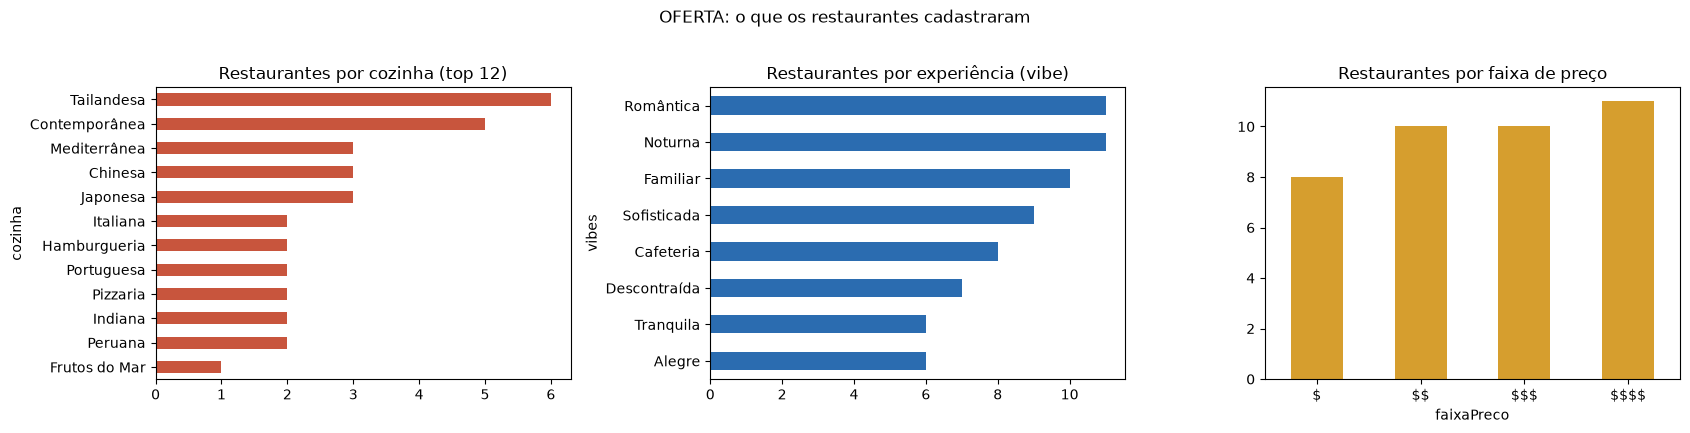

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
rest["cozinha"].value_counts().head(12).plot.barh(ax=ax[0], color="#c8553d"); ax[0].invert_yaxis()
ax[0].set_title("Restaurantes por cozinha (top 12)")
rest.explode("vibes")["vibes"].dropna().value_counts().plot.barh(ax=ax[1], color="#2b6cb0"); ax[1].invert_yaxis()
ax[1].set_title("Restaurantes por experiência (vibe)")
rest["faixaPreco"].map({1: "$", 2: "$$", 3: "$$$", 4: "$$$$"}).value_counts().reindex(["$", "$$", "$$$", "$$$$"]).plot.bar(ax=ax[2], color="#d69e2e", rot=0)
ax[2].set_title("Restaurantes por faixa de preço")
plt.suptitle("OFERTA: o que os restaurantes cadastraram", y=1.02); plt.tight_layout(); plt.show()

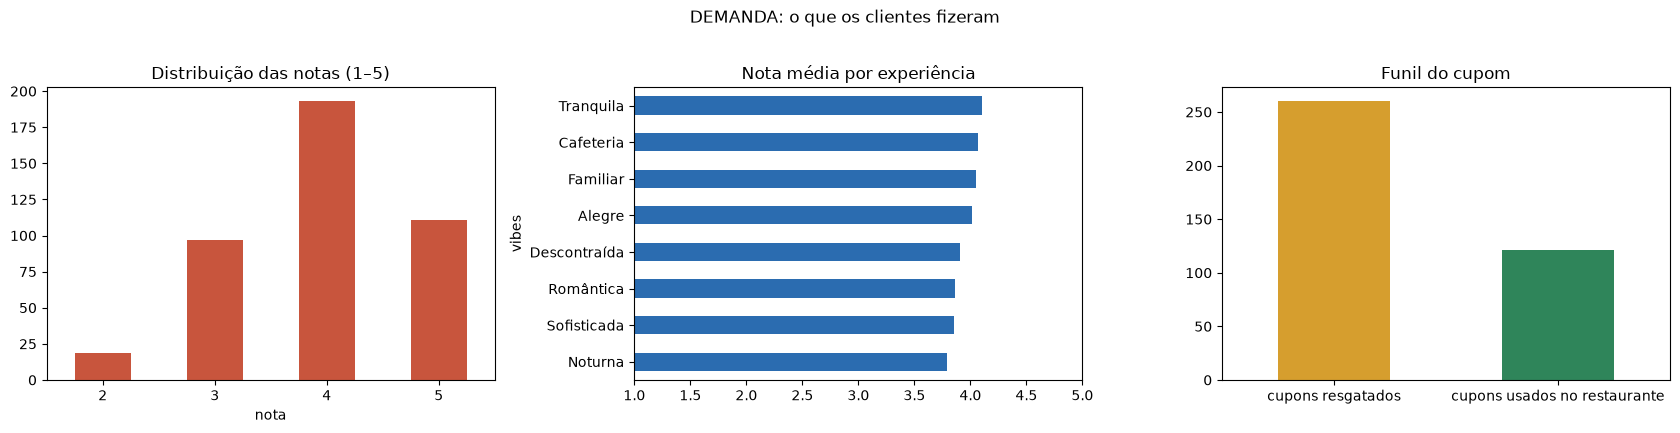

,mean,count
vibes,,
Noturna,3.79,111
Sofisticada,3.86,98
Romântica,3.86,113
Descontraída,3.91,87
Alegre,4.01,67
Familiar,4.05,104
Cafeteria,4.07,86
Tranquila,4.11,56


In [8]:
av = dfs["avaliacoes"]; rs = dfs["resgates"]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
av["nota"].value_counts().sort_index().plot.bar(ax=ax[0], color="#c8553d", rot=0); ax[0].set_title("Distribuição das notas (1–5)")

nota_vibe = (av[av["alvo"] == "restaurante"].merge(rest[["id", "vibes"]], left_on="restauranteId", right_on="id")
             .explode("vibes").groupby("vibes")["nota"].agg(["mean", "count"]).sort_values("mean"))
nota_vibe["mean"].plot.barh(ax=ax[1], color="#2b6cb0", xlim=(1, 5)); ax[1].set_title("Nota média por experiência")

funil = pd.Series({"cupons resgatados": len(rs), "cupons usados no restaurante": (rs["status"] == "usado").sum()})
funil.plot.bar(ax=ax[2], color=["#d69e2e", "#2f855a"], rot=0); ax[2].set_title("Funil do cupom")
plt.suptitle("DEMANDA: o que os clientes fizeram", y=1.02); plt.tight_layout(); plt.show()
nota_vibe.round(2)

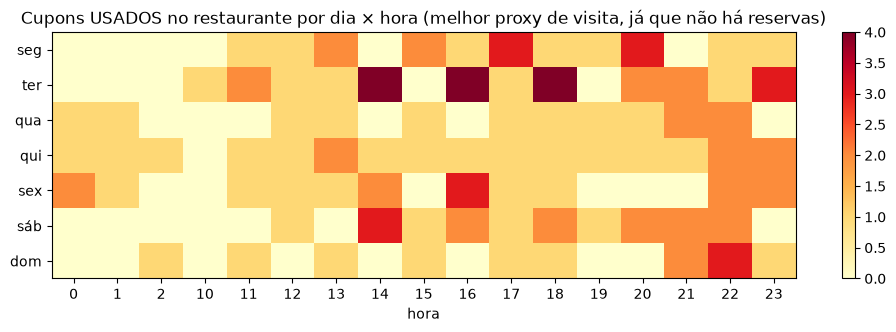

In [9]:
usado = pd.to_datetime(rs.loc[rs["status"] == "usado", "usadoEm"], errors="coerce").dropna()
dias = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
mapa = pd.crosstab(usado.dt.day_of_week.map(dict(enumerate(dias))), usado.dt.hour).reindex(dias)
fig, ax = plt.subplots(figsize=(12, 3.2))
im = ax.imshow(mapa.fillna(0), aspect="auto", cmap="YlOrRd")
ax.set_yticks(range(7), dias); ax.set_xticks(range(len(mapa.columns)), mapa.columns); ax.set_xlabel("hora")
ax.set_title("Cupons USADOS no restaurante por dia × hora (melhor proxy de visita, já que não há reservas)")
plt.colorbar(im, ax=ax); plt.show()

**Hipóteses levantadas na exploração** (são suposições para investigar, não conclusões):

- O resgate de cupom com QR validado (`status = "usado"`) é o **melhor indicador de visita real**. Ele pode substituir a reserva em P2, P3 e H2.
- Cruzar `avaliacoes` com `vibes` e `cozinha` do restaurante responde P4 diretamente.
- A **oferta** (o que os restaurantes cadastraram) não é igual à **demanda** (o que os clientes procuram). Sem registro de buscas, a demanda só aparece por salvos, resgates e avaliações.

## 4. Verificação de qualidade

In [10]:
problemas = []
def reg(col, verif, n, total, obs=""):
    problemas.append({"coleção": col, "verificação": verif, "ocorrências": int(n), "% do total": round(100 * n / max(total, 1), 1), "observação": obs})

todos_rest = u[u["tipo"] == "restaurante"]
reg("usuarios", "contas excluídas/banidas (filtrar antes de analisar)", (u["status"] != "ativo").sum(), len(u))
reg("usuarios", "restaurante ativo sem vibes", (rest["vibes"].str.len() == 0).sum(), len(rest), "não aparece no filtro de experiência")
for campo in ["cozinha", "faixaPreco", "bairro", "cidade"]:
    if campo in rest.columns:
        reg("usuarios", f"restaurante ativo sem {campo}", rest[campo].isna().sum(), len(rest))
fora = rest["cozinha"].dropna()[~rest["cozinha"].dropna().isin(COZINHAS)]
reg("usuarios", "cozinha fora da lista oficial", len(fora), len(rest), ", ".join(fora.unique()[:5]))
vfora = rest.explode("vibes")["vibes"].dropna(); vfora = vfora[~vfora.isin(EXPERIENCIAS)]
reg("usuarios", "vibe fora da lista oficial", len(vfora), len(rest), ", ".join(vfora.unique()[:5]))
if "cpf" in removidos["usuarios"] or "cnpj" in removidos["usuarios"]:
    reg("usuarios", "perfis antigos com CPF/CNPJ fora de 'privado' (migrar!)", 1, 1, "ver README, item 5 do checklist")

m = dfs["menus"]
reg("menus", "preço = 0", (m["preco"] <= 0).sum(), len(m))
q1, q3 = m["preco"].quantile([.25, .75]); lim = q3 + 3 * (q3 - q1)
reg("menus", f"preço atípico (> R$ {lim:.0f}, 3×IQR)", (m["preco"] > lim).sum(), len(m))
sem_menu = ~rest["id"].isin(m["restauranteId"])
reg("menus", "restaurante ativo sem nenhum prato", sem_menu.sum(), len(rest))

p = dfs["promocoes"]; vp = p.get("valorPromocional", pd.Series(dtype=str)).astype(str)
reg("promocoes", "valorPromocional como texto ('R$ …')", vp.str.startswith("R$").sum(), len(p), "precisa converter para número")
reg("promocoes", "valorPromocional vazio", (vp.str.strip().isin(["", "nan", "None"])).sum(), len(p))
k = dfs["cupons"]
reg("cupons", "desconto em formatos mistos (%, R$)", k["desconto"].astype(str).str.contains("R\\$").sum(), len(k), ", ".join(k["desconto"].astype(str).unique()[:6]))
cont = rs.groupby("cupomId").size().reindex(k["id"], fill_value=0).values
reg("cupons", "contador 'resgatados' ≠ resgates existentes", (k["resgatados"].fillna(0).values != cont).sum(), len(k))
reg("resgates", "status 'usado' sem data 'usadoEm'", ((rs["status"] == "usado") & rs["usadoEm"].isna()).sum(), len(rs))
reg("avaliacoes", "avaliação sem comentário", (av["comentario"].fillna("").str.strip() == "").sum(), len(av))
sem_av = ~rest["id"].isin(av["restauranteId"])
reg("avaliacoes", "restaurante ativo sem avaliação", sem_av.sum(), len(rest), "média com poucas notas é instável")

ids_rest = set(todos_rest["id"])
for c in ["menus", "promocoes", "cupons", "eventos", "salvos", "resgates", "avaliacoes"]:
    df = dfs[c]
    if "restauranteId" in df.columns:
        reg(c, "restauranteId sem restaurante", (~df["restauranteId"].isin(ids_rest)).sum(), len(df))
    reg(c, "documentos duplicados", df.drop(columns=["id"]).astype(str).duplicated().sum(), len(df))

qualidade = pd.DataFrame(problemas)
qualidade[qualidade["ocorrências"] > 0].reset_index(drop=True)

,coleção,verificação,ocorrências,% do total,observação
0,usuarios,contas excluídas/banidas (filtrar antes de ana...,2,1.1,
1,usuarios,restaurante ativo sem vibes,6,15.4,não aparece no filtro de experiência
2,menus,preço = 0,1,0.3,
3,menus,"preço atípico (> R$ 509, 3×IQR)",2,0.7,
4,promocoes,valorPromocional como texto ('R$ …'),12,30.0,precisa converter para número
5,promocoes,valorPromocional vazio,15,37.5,
6,cupons,"desconto em formatos mistos (%, R$)",11,22.0,"10%, R$ 10, 15%, 20%"
7,avaliacoes,avaliação sem comentário,126,30.0,


## 5. Os dados respondem às perguntas de negócio?

In [11]:
tem = lambda c, *cols: len(dfs[c]) > 0 and all(x in dfs[c].columns for x in cols)
pd.DataFrame([
    {"pergunta": "P1 culinárias e vibes mais buscadas/reservadas", "disponível?": "Parcial",
     "como responder": "Oferta (vibes/cozinha cadastradas) + demanda indireta (salvos, resgates, avaliações). Sem log de buscas."},
    {"pergunta": "P2 perfil de restaurante com maior conversão", "disponível?": "Proxy" if tem("resgates", "status") else "Não",
     "como responder": "Trocar 'visita→reserva' por 'cupom resgatado→usado' por vibe, faixa de preço, bairro e nota."},
    {"pergunta": "P3 dias e horários de maior demanda", "disponível?": "Proxy" if tem("resgates", "usadoEm") else "Não",
     "como responder": "resgates.usadoEm = hora em que o cliente estava no restaurante."},
    {"pergunta": "P4 avaliações × culinária/vibe", "disponível?": "Sim" if tem("avaliacoes", "nota") else "Não",
     "como responder": "avaliacoes × usuarios (vibes, cozinha): média, dispersão e quantidade por grupo."},
    {"pergunta": "P5 promoções/eventos com mais engajamento", "disponível?": "Sim" if tem("salvos") else "Não",
     "como responder": "salvos por promoção/evento + resgates por cupom ÷ limiteTotal."},
    {"pergunta": "H1 vibe é mais filtrada que culinária", "disponível?": "Não",
     "como responder": "Exige gravar os filtros aplicados (coleção 'buscas')."},
])

,pergunta,disponível?,como responder
0,P1 culinárias e vibes mais buscadas/reservadas,Parcial,Oferta (vibes/cozinha cadastradas) + demanda i...
1,P2 perfil de restaurante com maior conversão,Proxy,Trocar 'visita→reserva' por 'cupom resgatado→u...
2,P3 dias e horários de maior demanda,Proxy,resgates.usadoEm = hora em que o cliente estav...
3,P4 avaliações × culinária/vibe,Sim,"avaliacoes × usuarios (vibes, cozinha): média,..."
4,P5 promoções/eventos com mais engajamento,Sim,salvos por promoção/evento + resgates por cupo...
5,H1 vibe é mais filtrada que culinária,Não,Exige gravar os filtros aplicados (coleção 'bu...


## 6. Conclusões da Fase 2

> Revise depois de rodar com os dados de **produção**. Com `FONTE = "demo"`, os números acima são sintéticos.

1. **O sistema final tem dados ricos de oferta e de satisfação:** vibes, ocasiões, faixa de preço, localização, cardápio com preço, avaliações de 1 a 5 e resgates de cupom com validação por QR Code. Isso permite responder P4 e P5 e usar proxies para P2 e P3.
2. **O que falta:** reservas (vão pelo WhatsApp, fora da plataforma) e registro das buscas e filtros. A H1 não pode ser testada, e a P1 só pode ser respondida pela oferta, não pela procura.
3. **Volume:** PREENCHER com a quantidade de clientes, avaliações e resgates **reais** em produção. Se for pequena, a análise fica descritiva e com essa limitação declarada.
4. **Qualidade a tratar na Fase 3:** filtrar contas excluídas/banidas; converter `valorPromocional` e `desconto` em número; restaurantes sem vibe ou sem cardápio; médias de nota com poucas avaliações; conferir se perfis antigos ainda têm CPF/CNPJ fora de `privado`.
5. **Retorno à Fase 1 (ciclo CRISP-DM):** atualizar o documento de definição (coleções, campos e ambientes) e decidir se o sistema passa a gravar (a) os filtros usados e (b) o clique em "Reservar pelo WhatsApp", sem dados pessoais.